# 모델 만들기

**정상 이미지만으로** 학습해서 테스트 이미지마다 이상 맵 `(256, 256)` 과 점수를 내는 문제임.
위에서부터 차례로 따라가면 됨. 데이터를 먼저 둘러보려면 `1_eda.ipynb` 부터 보면 됨.

1. 카테고리 하나 잡기
2. 기준선 — 평균영상 거리
3. 칸 단위 특징
4. 패치 최근접 이웃
5. 맵에서 이미지 점수 뽑기
6. 전체로 돌려 보기 — 점수 분포, 임계값, ROC, PRO 곡선, 사례
7. 맵이 결함을 제대로 짚었나
8. 사전학습 CNN 특징
9. `model.py` 채우기

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'example' else Path.cwd()))
warnings.filterwarnings('ignore')
_ko = [f for f in ['NanumGothic', 'Noto Sans CJK KR', 'Noto Serif CJK KR', 'AppleGothic', 'Malgun Gothic']
       if any(f == x.name for x in font_manager.fontManager.ttflist)]
plt.rcParams['font.family'] = _ko[:1] + ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

from src import Dataset, run, predict, report, evaluate, threshold, metrics, ARTIFACTS
from src.explain import show, occlusion, agreement
from src.evaluate import localization

ds = Dataset()
ds

Dataset(dataset/: 38개 카테고리, 47,403 장)

## 1. 카테고리 하나 잡기

먼저 `limit` 으로 앞의 몇 장만 써서 끝까지 빠르게 한 번 돌려 봄.
`limit` 을 주면 val 은 정상과 불량을 반반 고름.

In [2]:
cat = ds.category('agri_02')
LIMIT = 200
cat

Category(agri_02: train 1000 / val 149 장 (불량 49) / test 0 장)

## 2. 기준선 — 평균영상 거리

`src/model.py` 기본값임. 정상 이미지들의 평균에서 픽셀마다 얼마나 먼지를 맵으로 씀.

train 정상 이미지 $I_1, \dots, I_N$ 의 평균 영상과, 새 이미지 $I$ 의 이상 맵 $A$ 는

$$
\mu(u, v) = \frac{1}{N} \sum_{i=1}^{N} I_i(u, v), \qquad
A(u, v) = \lVert I(u, v) - \mu(u, v) \rVert_2^2
$$

$(u, v)$ 는 픽셀 위치, $I(u, v)$ 는 RGB 3개 값임. 이미지 점수는 맵의 최댓값 $s = \max_{u,v} A(u, v)$.

`run` 은 실험용임. 새 모델을 train 으로 `fit` 하고, val 정상 점수로 임계값을 정한 뒤 val 의 맵과
점수를 냄. 학습된 모델이 이미 있으면 `predict(model, cat, "val")` 을 씀.

In [3]:
from src import Model

res, maps, thr = run(Model, cat, limit=LIMIT)
masks = cat.masks(res)
base = report(res, masks, maps)
{k: round(v, 3) for k, v in base.items()}

  agri_02: 학습 0초, 전체 2초


{'image_auroc': 0.432,
 'f1': 0.0,
 'precision': 0.0,
 'recall': 0.0,
 'n_images': 149,
 'pixel_aupro': 0.236,
 'pixel_auroc': 0.635,
 'mean_iou': 0.042,
 'wrong_place': 0}

0.5 근처임. 위치도 질감도 보지 않아서 정상 개체끼리의 차이와 결함을 구분하지 못함.
**여기에 못 미치면 모델이 아무 일도 안 한 것임.**

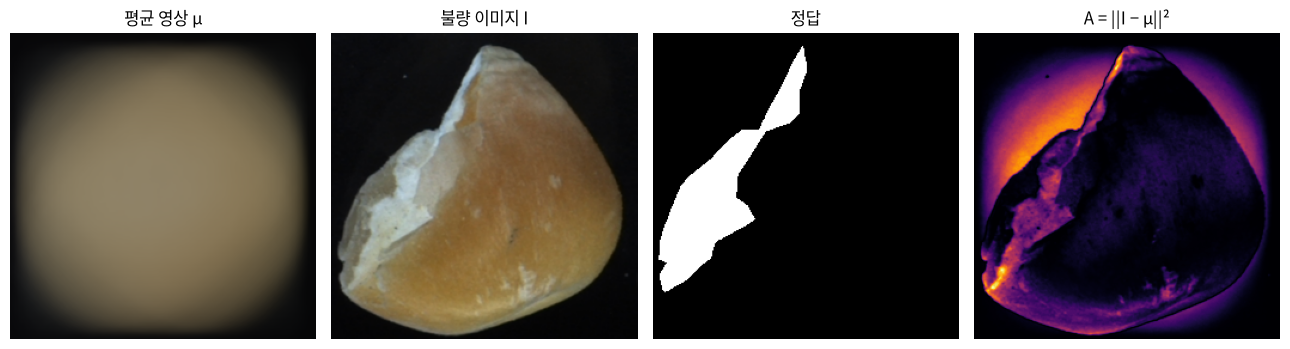

In [4]:
m0 = Model().fit(cat.images('train'))
i_bad = res.index[res.is_anomaly == 1][0]
x = cat.images(res.loc[[i_bad]])[0]

fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
ax[0].imshow(m0.mean.astype(np.uint8)); ax[0].set_title('평균 영상 μ')
ax[1].imshow(x); ax[1].set_title('불량 이미지 I')
ax[2].imshow(masks[i_bad], cmap='gray'); ax[2].set_title('정답')
ax[3].imshow(maps[i_bad], cmap='inferno'); ax[3].set_title('A = ||I − μ||²')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

평균 영상이 흐릿한 얼룩임. 물체의 모양과 위치가 이미지마다 달라서 평균을 내면 뭉개짐.
그래서 맵은 결함이 아니라 **물체가 평균과 어긋난 자리** 전체에서 큼.

## 3. 칸 단위 특징

`patch_stats` 는 8×8 칸마다 색 평균·표준편차와 그래디언트를 잼. `(n, 256, 256, 3)` 이
`(n, 32, 32, 8)` 이 됨.

칸 $P$ (픽셀 64개) 하나의 특징 벡터 $f(P) \in \mathbb{R}^8$ 은

$$
f(P) = \big[\, \bar{I}_R,\ \bar{I}_G,\ \bar{I}_B,\ \sigma_R,\ \sigma_G,\ \sigma_B,\ \bar{g},\ \sigma_g \,\big],
\qquad g(u, v) = \lVert \nabla \mathrm{gray}(u, v) \rVert
$$

$\bar{\cdot}$ 는 칸 안의 평균, $\sigma$ 는 표준편차, $g$ 는 밝기의 그래디언트 크기(경계의 세기)임.
얼룩·변색은 색 평균에, 균열·스크래치는 그래디언트에 드러남. **공간 축을 유지하는 것이 핵심임.** 전역 평균으로 뭉개면 맵을 못 만듦.

(1, 256, 256, 3) -> (1, 32, 32, 8)


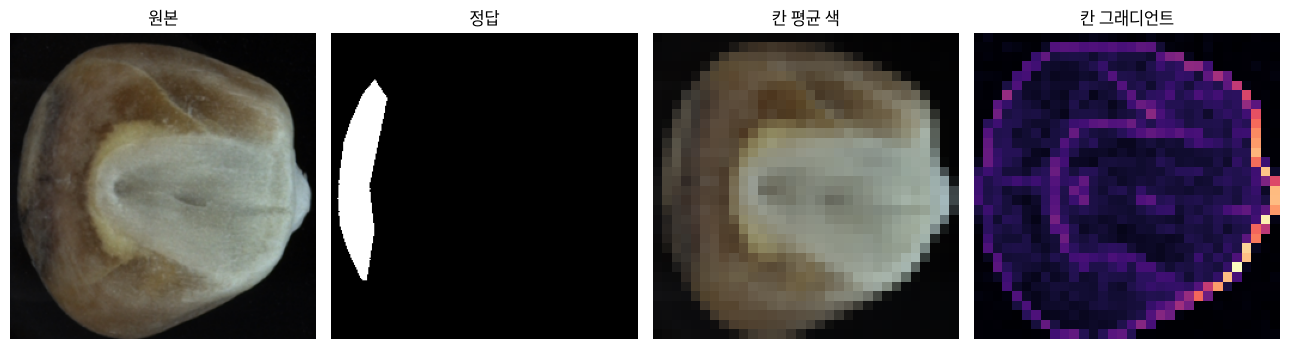

In [5]:
from src.features import patch_stats, upsample, blur

row = res[res.is_anomaly == 1].sort_values('mask_area_pct').iloc[len(res) // 8]
x = cat.images(res.loc[[row.name]])
f = patch_stats(x)
print(x.shape, '->', f.shape)

fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
ax[0].imshow(x[0]); ax[0].set_title('원본')
ax[1].imshow(cat.masks(res.loc[[row.name]])[0], cmap='gray'); ax[1].set_title('정답')
ax[2].imshow(f[0, ..., :3]); ax[2].set_title('칸 평균 색')
ax[3].imshow(f[0, ..., 6], cmap='magma'); ax[3].set_title('칸 그래디언트')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 4. 패치 최근접 이웃

정상 이미지의 칸들을 전부 모아 메모리뱅크로 둠. 테스트 칸마다 **가장 가까운 정상 칸까지의 거리**가
그 칸의 이상 점수임. PatchCore 를 아주 단순하게 줄인 것이고 `example/sample_model.py` 에 있음.

정상 칸들의 특징을 모은 메모리뱅크를 $\mathcal{B} = \{ b_1, \dots, b_M \}$ 라 하면,
새 이미지의 칸 $P$ 의 이상 점수와 이미지 점수는

$$
A(P) = \min_{b \in \mathcal{B}} \lVert \tilde f(P) - b \rVert_2, \qquad
s = \frac{1}{k} \sum_{\text{상위 } k \text{ 칸}} A(P)
$$

$\tilde f$ 는 정상 기준으로 표준화한 특징(특징마다 단위가 달라서), $k$ 는 맵의 상위 1% 임.
$32 \times 32$ 격자 점수를 256 으로 펼치고 가우시안 블러를 걸어 맵을 만듦.

정상 칸 중 비슷한 게 하나라도 있으면 점수가 낮음. 그래서 위치나 방향이 조금 달라도, 정상 개체끼리
모양이 달라도 버팀. 역전파 학습이 없어서 CPU 로 금방 돌아감.

In [6]:
from sample_model import SampleModel

res_nn, maps_nn, thr_nn = run(SampleModel, cat, limit=LIMIT)
nn = report(res_nn, masks, maps_nn)

pd.DataFrame({'평균영상': base, '패치 최근접': nn}).loc[
    ['image_auroc', 'pixel_aupro', 'f1', 'mean_iou']].round(3)

  agri_02: 학습 1초, 전체 22초


,평균영상,패치 최근접
image_auroc,0.432,0.641
pixel_aupro,0.236,0.621
f1,0.000,0.214
mean_iou,0.042,0.104


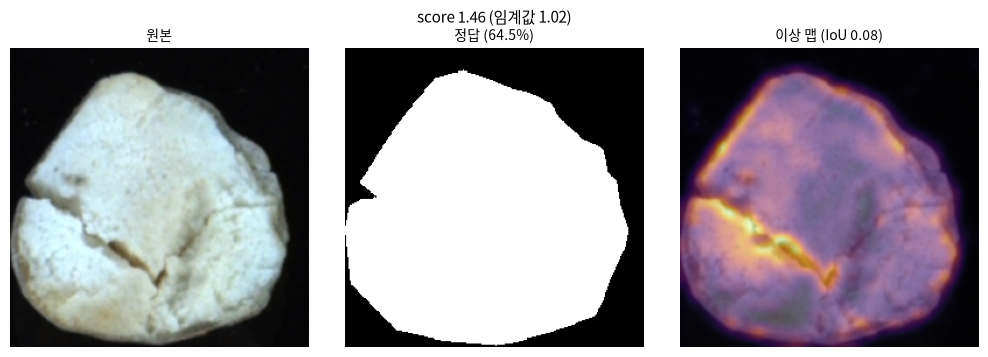

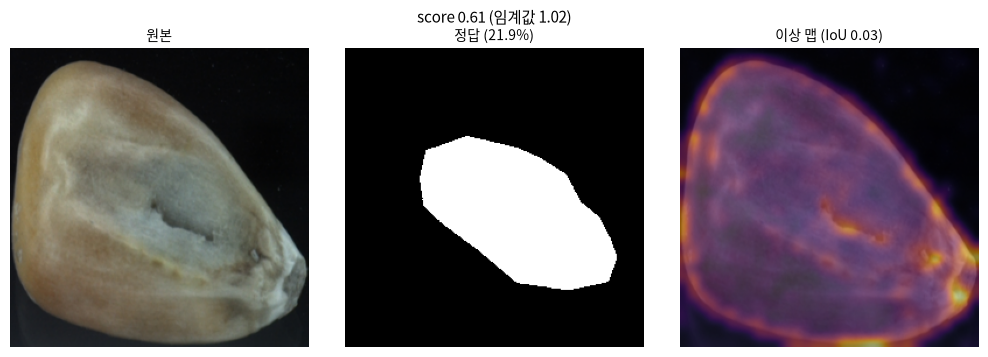

In [7]:
order = res_nn[res_nn.is_anomaly == 1].sort_values('score', ascending=False)
for i in [order.index[0], order.index[len(order) // 2]]:
    show(cat.images(res_nn.loc[[i]])[0], masks[i], maps_nn[i],
         title=f'score {res_nn.score[i]:.2f} (임계값 {thr_nn:.2f})')
plt.show()

### 메모리뱅크를 2차원으로 펴 보기

특징은 8차원이라 눈으로 볼 수 없음. PCA 로 2차원에 펴서 정상 칸(메모리뱅크)과 불량 이미지의
결함 칸·정상 칸이 어디에 놓이는지 봄. 결함 칸이 뱅크 바깥에 있으면 거리가 커서 잡힘.

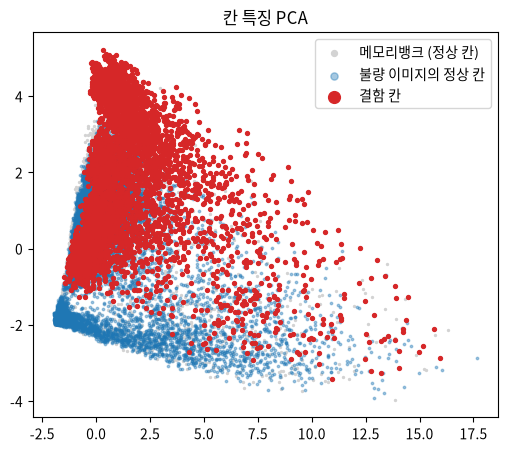

In [8]:
from sklearn.decomposition import PCA

m_nn = SampleModel().fit(cat.images('train', LIMIT))
bad_rows = res_nn[res_nn.is_anomaly == 1].head(20)
f = m_nn._features(cat.images(bad_rows)).reshape(-1, 8)
inside = cat.masks(bad_rows).reshape(len(bad_rows), 32, 8, 32, 8).mean(axis=(2, 4)).ravel() > 0.5

pca = PCA(2).fit(m_nn.bank)
B, F = pca.transform(m_nn.bank[::4]), pca.transform(f)
plt.figure(figsize=(6, 5))
plt.scatter(*B.T, s=2, c='lightgray', label='메모리뱅크 (정상 칸)')
plt.scatter(*F[~inside].T, s=3, c='tab:blue', alpha=0.4, label='불량 이미지의 정상 칸')
plt.scatter(*F[inside].T, s=8, c='tab:red', label='결함 칸')
plt.legend(markerscale=3); plt.title('칸 특징 PCA'); plt.show()

### 하이퍼파라미터

`cell` 은 칸 크기임. 작을수록 작은 결함을 잡지만 잡음도 늘어남.
`bank_size` 는 메모리뱅크 크기임. 크면 정확하지만 느림.

val 로 고름. 다만 val 에서 많이 고를수록 val 점수는 낙관적이 됨. 채점은 비공개 test 로 하니
val 에만 맞춘 설정은 거기서 떨어짐. 후보를 적게 두고, 여러 카테고리에서 고르게 좋은 값을 고를 것.

여기서는 보여 주기 위해 agri_04 하나로만 비교함. 실제로는 여러 도메인의 카테고리를 함께 보고 평균이
고르게 좋은 값을 골라야 함.

In [9]:
tune = ds.category('agri_04')     # 예시라 하나만. 실제로는 여러 카테고리를 함께 볼 것
rows = []
for cell in [8, 16]:
    for bank in [5000, 20000]:
        r, mp, _ = run(lambda: SampleModel(cell=cell, bank_size=bank), tune,
                       limit=LIMIT, verbose=False)
        rep = report(r, tune.masks(r), mp)
        rows.append({'cell': cell, 'bank': bank, 'image_auroc': rep['image_auroc'],
                     'pixel_aupro': rep['pixel_aupro']})
pd.DataFrame(rows).round(3)

,cell,bank,image_auroc,pixel_aupro
0,8,5000,0.588,0.622
1,8,20000,0.636,0.645
2,16,5000,0.668,0.623
3,16,20000,0.736,0.642


## 5. 맵에서 이미지 점수 뽑기

뽑는 방법은 자유임. 최댓값은 칸 하나의 잡음에 통째로 흔들리고,
상위 k% 평균은 같은 발상이면서 더 안정적임.

In [10]:
flat = maps_nn.reshape(len(maps_nn), -1)
y = res_nn.is_anomaly
for name, s in {'max': flat.max(1),
                '상위 1% 평균': np.sort(flat, 1)[:, -655:].mean(1),
                '상위 5% 평균': np.sort(flat, 1)[:, -3277:].mean(1),
                '전체 평균': flat.mean(1)}.items():
    print(f'{name:10} image AUROC {metrics.auroc(y, s):.3f}')

max        image AUROC 0.592
상위 1% 평균   image AUROC 0.641
상위 5% 평균   image AUROC 0.700
전체 평균      image AUROC 0.893


결과가 직관과 다를 수 있음. 맵 **전체 평균**이 높게 나온다면, 결함이 아니라 다른 무언가(물체 크기,
밝기, 배경 면적)를 재고 있을 가능성이 있음. 결함은 이미지의 몇 % 에 불과한데 전체 평균이 그걸 잘
잡는다는 건 이상한 일임. **이미지를 열어서 확인할 것.** 숫자가 좋다고 맞는 이유로 좋은 건 아님.

## 6. 전체로 돌려 보기

`limit` 없이 카테고리 전체로 돌림. 그다음 점수가 어떻게 지표가 되는지 하나씩 그려 봄.

In [11]:
full, full_maps, _ = run(SampleModel, cat)
full_masks = cat.masks(full)
{k: round(v, 3) for k, v in report(full, full_masks, full_maps).items()}

  agri_02: 학습 6초, 전체 26초


{'image_auroc': 0.605,
 'f1': 0.182,
 'precision': 0.833,
 'recall': 0.102,
 'n_images': 149,
 'pixel_aupro': 0.618,
 'pixel_auroc': 0.835,
 'mean_iou': 0.106,
 'wrong_place': 0}

In [12]:
metrics.by_defect_size(full).round(3)

,구간,n,auroc
0,소 (0.0~1.0%),6,0.815
1,중 (1.0~5.0%),10,0.656
2,대 (5.0~100.0%),33,0.551


작은 결함일수록 어려움. 평균 하나만 보면 이게 가려짐.

### 점수 분포와 임계값

판정은 점수가 임계값 $\tau$ 를 넘는지로 함. $\hat y = \mathbb{1}[\, s \ge \tau \,]$

**$\tau$ 는 팀이 정함.** `load_model()` 이 돌려준 모델에 `threshold` 속성을 두면 그 값을 쓰고,
없으면 기본값으로 val 정상 이미지 점수의 99% 분위수를 씀. 정상의 1% 만 넘도록 잡은 선임.

$$
\tau_{\text{기본}} = Q_{0.99}\big(\{ s_i : y_i = 0 \}\big)
$$

이 판정으로 F1 을 잼. 정밀도 $P$ 는 불량이라 한 것 중 진짜 불량의 비율, 재현율 $R$ 은 진짜 불량 중 잡은 비율임.

$$
F_1 = \frac{2PR}{P + R}
$$

두 분포가 많이 겹칠수록 어떤 임계값을 잡아도 놓치거나 과검출함. 아래 숫자는 $\tau$ 를 정한 val 로
다시 잰 것이라 낙관적임. 채점은 처음 보는 test 에서 같은 $\tau$ 로 함.

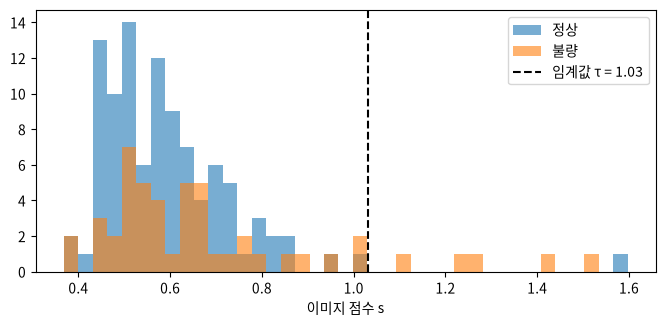

{'f1': 0.182, 'precision': 0.833, 'recall': 0.102}


In [13]:
thr_full = threshold(full.score[full.is_anomaly == 0])
bins = np.linspace(full.score.min(), full.score.max(), 40)
plt.figure(figsize=(8, 3.4))
plt.hist(full.score[full.is_anomaly == 0], bins, alpha=0.6, label='정상')
plt.hist(full.score[full.is_anomaly == 1], bins, alpha=0.6, label='불량')
plt.axvline(thr_full, color='k', ls='--', label=f'임계값 τ = {thr_full:.2f}')
plt.xlabel('이미지 점수 s'); plt.legend(); plt.show()
print({k: round(v, 3) for k, v in metrics.f1(full.is_anomaly, full.score >= thr_full).items()})

### ROC 와 AUROC

임계값을 끝에서 끝까지 움직이며 (정상을 불량이라 한 비율, 불량을 잡은 비율) 을 그린 곡선이 ROC 임.
그 아래 넓이가 AUROC 이고, **불량 하나와 정상 하나를 무작위로 뽑았을 때 불량 점수가 더 높을 확률**과 같음.

$$
\mathrm{AUROC} = P\big( s_{\text{불량}} > s_{\text{정상}} \big)
$$

0.5 는 동전 던지기, 1.0 은 완벽히 갈림. 임계값을 정하지 않아도 되는 지표라 주 지표로 씀.

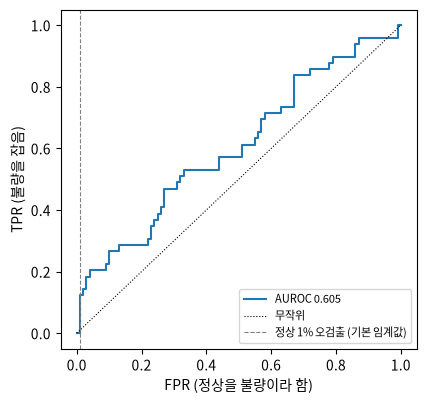

In [14]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(full.is_anomaly, full.score)
plt.figure(figsize=(4.6, 4.4))
plt.plot(fpr, tpr, label=f'AUROC {metrics.auroc(full.is_anomaly, full.score):.3f}')
plt.plot([0, 1], [0, 1], 'k:', lw=0.8, label='무작위')
plt.axvline(0.01, color='gray', lw=0.8, ls='--', label='정상 1% 오검출 (기본 임계값)')
plt.xlabel('FPR (정상을 불량이라 함)'); plt.ylabel('TPR (불량을 잡음)'); plt.legend(fontsize=8); plt.show()

### PRO 곡선과 AUPRO

AUROC 는 이미지 단위임. 위치를 재려면 픽셀을 봐야 하는데, 픽셀을 그대로 세면 큰 결함이 표를
독차지함. PRO 는 **결함 영역마다 따로** 얼마나 덮였는지 재고 평균함.

정답 마스크의 결함 영역(연결된 덩어리)을 $R_1, \dots, R_K$ 라 하면, 맵 임계값 $t$ 에서

$$
\mathrm{PRO}(t) = \frac{1}{K} \sum_{k=1}^{K} \frac{ \lvert R_k \cap \{ A \ge t \} \rvert }{ \lvert R_k \rvert },
\qquad
\mathrm{FPR}(t) = \frac{ \lvert \{ A \ge t \} \setminus R \rvert }{ \lvert \text{정상 픽셀} \rvert }
$$

$t$ 를 낮추며 (FPR, PRO) 를 그리고, FPR 0.3 까지의 넓이를 0.3 으로 나눈 것이 AUPRO 임.
작은 결함도 큰 결함과 같은 무게로 들어감.

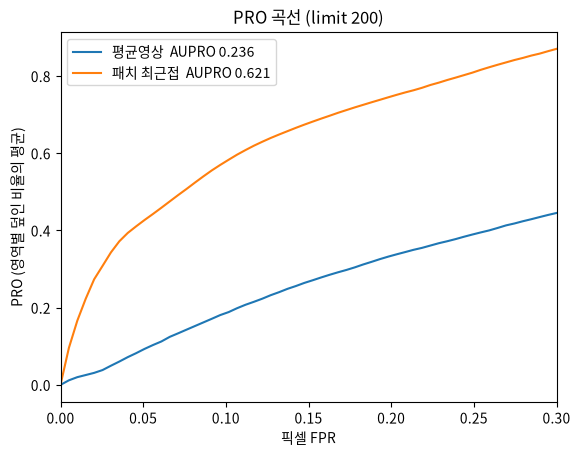

In [15]:
from scipy import ndimage

def pro_curve(masks, maps, n_steps=60, fpr_limit=0.3):
    regions = []
    for m, a in zip(masks > 0, maps):
        lab, k = ndimage.label(m)
        regions += [a[lab == r] for r in range(1, k + 1)]
    normal = maps[masks == 0]
    out = []
    for t in np.quantile(normal, np.linspace(1.0, 1 - fpr_limit, n_steps)):
        out.append(((normal >= t).mean(), np.mean([(v >= t).mean() for v in regions])))
    return np.array(out)

for name, (r, mp) in {'평균영상': (res, maps), '패치 최근접': (res_nn, maps_nn)}.items():
    c = pro_curve(cat.masks(r), mp)
    plt.plot(c[:, 0], c[:, 1], label=f'{name}  AUPRO {metrics.aupro(cat.masks(r), mp):.3f}')
plt.xlabel('픽셀 FPR'); plt.ylabel('PRO (영역별 덮인 비율의 평균)')
plt.xlim(0, 0.3); plt.legend(); plt.title(f'PRO 곡선 (limit {LIMIT})'); plt.show()

### 사례 갤러리 — 맞힌 것, 과검출, 미검출

숫자 뒤에 있는 이미지를 봄. 해석 단계의 출발점임.

- **맞힌 불량**: 점수가 가장 높은 불량
- **과검출**: 점수가 가장 높은 정상. 왜 이상하다고 봤는가
- **미검출**: 점수가 가장 낮은 불량. 왜 못 봤는가

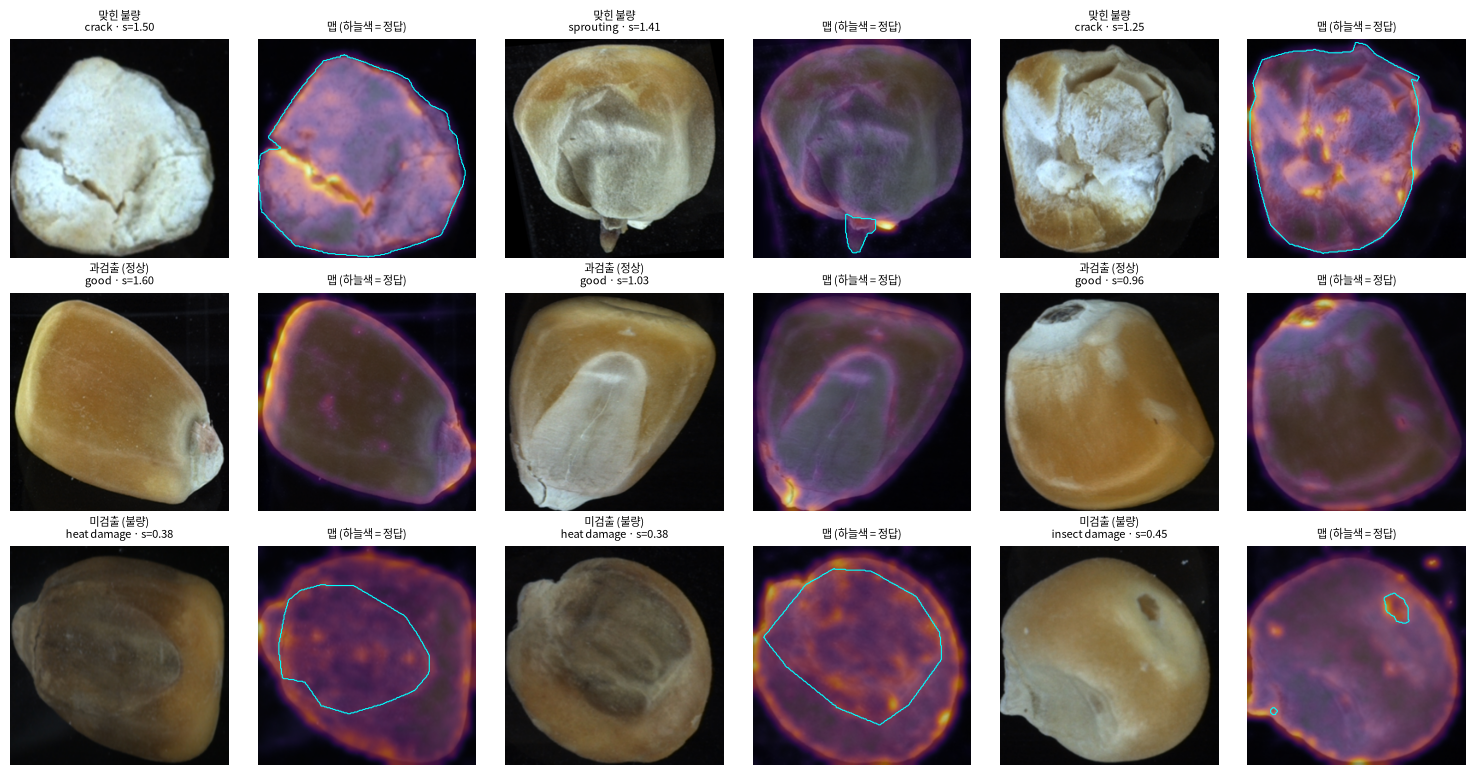

In [16]:
cases = {'맞힌 불량': full[full.is_anomaly == 1].nlargest(3, 'score').index,
         '과검출 (정상)': full[full.is_anomaly == 0].nlargest(3, 'score').index,
         '미검출 (불량)': full[full.is_anomaly == 1].nsmallest(3, 'score').index}
fig, ax = plt.subplots(3, 6, figsize=(15, 7.8))
for r, (name, idx) in enumerate(cases.items()):
    x = cat.images(full.loc[idx])
    for j, i in enumerate(idx):
        ax[r, 2 * j].imshow(x[j])
        ax[r, 2 * j].set_title(f'{name}\n{full.label[i]} · s={full.score[i]:.2f}', fontsize=8)
        ax[r, 2 * j + 1].imshow(x[j]); ax[r, 2 * j + 1].imshow(full_maps[i], cmap='inferno', alpha=0.55)
        if full_masks[i].any():
            ax[r, 2 * j + 1].contour(full_masks[i], [0.5], colors='cyan', linewidths=0.8)
        ax[r, 2 * j + 1].set_title('맵 (하늘색 = 정답)', fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 7. 맵이 결함을 제대로 짚었나

**점수를 맞히는 것과 제대로 보는 것은 다름.** 맵 상위 5% 영역 $T$ 를 "모델이 본 곳"으로 보고
정답 마스크 $M$ 과 비교함.

$$
\mathrm{IoU} = \frac{|T \cap M|}{|T \cup M|}, \qquad
\text{hit\_rate} = \frac{|T \cap M|}{|T|}, \qquad
\text{mask\_coverage} = \frac{|T \cap M|}{|M|}
$$

`wrong_place` 는 불량으로 걸러냈는데($s \ge \tau$) IoU 가 0.05 보다 작은 이미지 수임.

In [17]:
loc = localization(full, full_maps, full_masks)
print(f'불량 {len(loc)}장, 평균 IoU {loc.iou.mean():.3f}')
wrong = loc[(loc.pred == 1) & (loc.iou < 0.05)]
print(f'불량으로 걸러냈지만 맵이 결함과 거의 안 겹친 이미지 {len(wrong)}장')
loc.sort_values('iou').head()

불량 49장, 평균 IoU 0.106
불량으로 걸러냈지만 맵이 결함과 거의 안 겹친 이미지 0장


,i,path,pred,iou,hit_rate,mask_coverage
42,142,agriculture/agri_02/val/spot/0003.png,0,0.007317,0.015873,0.013392
12,112,agriculture/agri_02/val/insect damage/0003.png,0,0.008380,0.009158,0.089820
26,126,agriculture/agri_02/val/mildew/0007.png,0,0.008519,0.026252,0.012455
33,133,agriculture/agri_02/val/multi_anomalies/0001.png,0,0.014693,0.071734,0.018143
6,106,agriculture/agri_02/val/heat damage/0001.png,0,0.022966,0.193223,0.025401


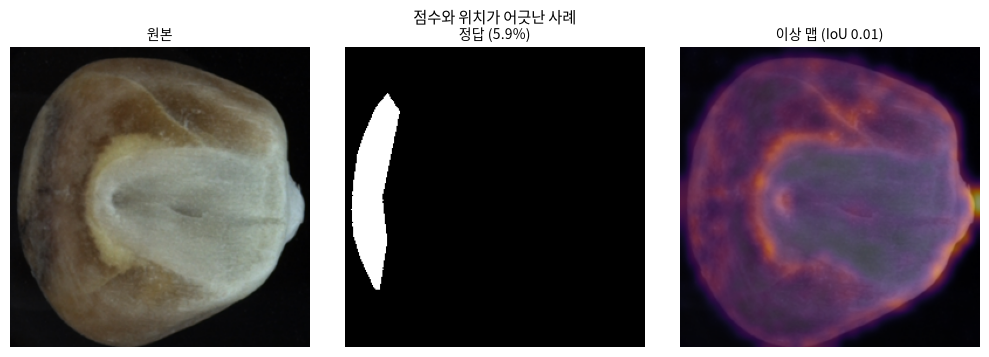

In [18]:
i = wrong.i.iloc[0] if len(wrong) else loc.i[loc.iou.idxmin()]
show(cat.images(full.loc[[i]])[0], full_masks[i], full_maps[i],
     title='점수와 위치가 어긋난 사례')
plt.show()

이런 사례가 많으면 그 AUROC 는 우연임. 새 결함 유형이 들어오면 바로 무너짐.
왜 여기를 봤는지(조명? 그림자? 물체 경계?)를 찾는 것이 해석 단계의 출발점임.

### 사후 해석과 비교

`occlusion` 은 칸을 가려 가며 점수가 얼마나 떨어지는지 잼. 모델 내부를 보지 않아서 어떤
모델에나 붙음. 내장 맵과 같은 곳을 가리키는지 봄. 한 장에 수백 번 추론하니 소수에만 씀.

내장 맵            {'iou': 0.312, 'hit_rate': 0.478, 'mask_coverage': 0.473}
occlusion (blur)   {'iou': 0.638, 'hit_rate': 0.783, 'mask_coverage': 0.775}
occlusion (mean)   {'iou': 0.084, 'hit_rate': 0.156, 'mask_coverage': 0.155}


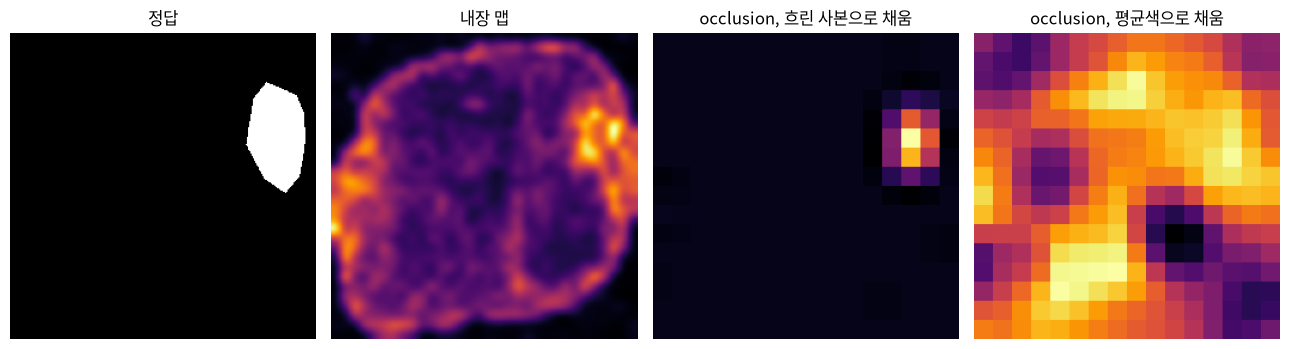

In [19]:
model = SampleModel(bank_size=5000).fit(cat.images('train', 400))
j = loc.i[loc.iou.idxmax()]
img = cat.images(full.loc[[j]])[0]
occ = occlusion(model.score, img)

occ_mean = occlusion(model.score, img, fill='mean')

print('내장 맵           ', {k: round(v, 3) for k, v in agreement(full_maps[j], full_masks[j]).items()})
print('occlusion (blur)  ', {k: round(v, 3) for k, v in agreement(occ, full_masks[j]).items()})
print('occlusion (mean)  ', {k: round(v, 3) for k, v in agreement(occ_mean, full_masks[j]).items()})
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
ax[0].imshow(full_masks[j], cmap='gray'); ax[0].set_title('정답')
ax[1].imshow(full_maps[j], cmap='inferno'); ax[1].set_title('내장 맵')
ax[2].imshow(occ, cmap='inferno'); ax[2].set_title('occlusion, 흐린 사본으로 채움')
ax[3].imshow(occ_mean, cmap='inferno'); ax[3].set_title('occlusion, 평균색으로 채움')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

같은 occlusion 이라도 **가린 자리를 무엇으로 채우느냐**에 따라 결과가 달라짐. 평균색으로 채우면
검은 배경 위의 회색 칸 자체가 새로운 이상이 되어 점수를 올리고, 맵이 결함과 엇나감.
흐린 사본으로 채우면 실제로 있을 법한 이미지에 가까워짐. `occlusion` 의 기본값이 흐린 사본인 이유임.

**사후 해석도 맞는지 확인해야 함.** 채우는 값과 패치 크기를 바꿔 가며 정답 마스크와 대조하고,
보고서에는 어떤 설정을 썼는지 적을 것.

## 8. 사전학습 CNN 특징

`patch_stats` 는 색과 경계만 봄. ImageNet 으로 학습한 ResNet 의 중간층은 질감과 모양을 훨씬
풍부하게 담음. PaDiM, PatchCore 가 쓰는 특징임.

`resnet()` 은 처음 한 번 가중치를 내려받아 `artifacts/resnet18.pt` 에 저장함.

In [20]:
from src.features import resnet, cnn_features

net = resnet()
f = cnn_features(net, cat.images('train', 4))
print(f.shape, '  layer2(128) + layer3(256), 격자 32x32')

(4, 32, 32, 384)   layer2(128) + layer3(256), 격자 32x32


`SampleModel._features` 를 `cnn_features` 로 바꾸면 그대로 PatchCore 에 가까워짐.
특징 차원이 384 라 메모리뱅크가 커지니 `bank_size` 를 줄이거나 coreset 으로 고를 것.

## 9. `model.py` 채우

```python
# src/model.py
class Model:
    def fit(self, images): ...
    def score_map(self, images): ...
    def score(self, images): ...
    def save(self, folder): ...
    @classmethod
    def load(cls, folder): ...

def train(category, images):          # main.py train 이 부름
    Model().fit(images).save(ARTIFACTS / category)

def load_model(category):             # 채점자가 부름
    return Model.load(ARTIFACTS / category)
```

학습은 어디서 해도 됨(노트북, Colab, 대여 GPU). 결과를 `artifacts/<category>/` 에 저장하면 됨.
채점 때는 학습을 다시 돌리지 않고 `load_model()` 로 불러 추론만 함.

학습된 모델을 불러 val 로 점수를 내 보면 아래와 같음.

In [21]:
from sample_model import SampleModel

folder = ARTIFACTS / 'example' / cat.name           # 예시라 따로 저장
SampleModel().fit(cat.images('train')).save(folder)

model = SampleModel.load(folder)                     # 채점자가 하는 일
res, maps, thr = predict(model, cat, 'val')
{k: round(v, 3) for k, v in report(res, cat.masks(res), maps).items()}

{'image_auroc': 0.605,
 'f1': 0.182,
 'precision': 0.833,
 'recall': 0.102,
 'n_images': 149,
 'pixel_aupro': 0.618,
 'pixel_auroc': 0.835,
 'mean_iou': 0.106,
 'wrong_place': 0}

`src/model.py` 를 고쳤으면 출력 형식부터 확인함.

```bash
python main.py train                # 38개 카테고리를 학습해 artifacts/ 에 저장
python main.py check                # 제출 형식 검사
python main.py eval --limit 200     # 빠르게
python main.py eval                 # 전체
```